#### Uma empresa de telecomunicações quer saber quais clientes têm maior chance de cancelar o serviço (churn) nos próximos 30 dias. Com essa informação, o time de retenção pode agir antes da saída do cliente.

#### Seu trabalho é construir um modelo de classificação que preveja se um cliente vai cancelar (Churn = 1) ou não (Churn = 0).

In [2]:
# Importar Database
# Visualizar os dados
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt

df_churn = pd.read_csv("churn_dataset.csv")
display(df_churn)
display(df_churn.info())
display(df_churn.describe())


,cliente_id,tempo_contrato_meses,valor_mensal,num_chamadas_suporte,tipo_contrato,plano_internet,tem_suporte_tecnico,tem_backup_online,num_produtos_contratados,metodo_pagamento,atraso_pagamento_dias,Churn
0,1001,11,102.44,0,Mensal,Fibra,Não,Não,2,Débito automático,2,1
1,1002,27,46.49,0,Bienal,DSL,Sim,Não,4,Boleto,2,0
2,1003,33,82.42,1,Anual,Sem internet,Não,Não,5,Cartão,3,0
3,1004,48,56.92,3,Anual,Fibra,Não,Sim,2,Boleto,2,0
4,1005,19,112.92,1,Mensal,Sem internet,Não,Não,5,Boleto,3,1
...,...,...,...,...,...,...,...,...,...,...,...,...
3495,4496,19,118.15,1,Mensal,DSL,Não,Sim,2,Boleto,5,1
3496,4497,45,37.01,1,Bienal,DSL,Não,Não,2,Cartão,1,0
3497,4498,45,59.56,2,Bienal,Sem internet,Sim,Não,1,Cartão,2,0
3498,4499,5,99.23,0,Mensal,Fibra,Sim,Não,3,Boleto,1,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3500 entries, 0 to 3499
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   cliente_id                3500 non-null   int64  
 1   tempo_contrato_meses      3500 non-null   int64  
 2   valor_mensal              3500 non-null   float64
 3   num_chamadas_suporte      3500 non-null   int64  
 4   tipo_contrato             3500 non-null   object 
 5   plano_internet            3500 non-null   object 
 6   tem_suporte_tecnico       3500 non-null   object 
 7   tem_backup_online         3500 non-null   object 
 8   num_produtos_contratados  3500 non-null   int64  
 9   metodo_pagamento          3500 non-null   object 
 10  atraso_pagamento_dias     3500 non-null   int64  
 11  Churn                     3500 non-null   int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 328.3+ KB


None

,cliente_id,tempo_contrato_meses,valor_mensal,num_chamadas_suporte,num_produtos_contratados,atraso_pagamento_dias,Churn
count,3500.000000,3500.00000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000
mean,2750.500000,27.08600,79.268546,1.532286,3.004286,1.978857,0.374286
std,1010.507298,19.81862,28.819582,1.230896,1.390464,1.418092,0.484007
min,1001.000000,1.00000,30.000000,0.000000,1.000000,0.000000,0.000000
25%,1875.750000,12.00000,53.835000,1.000000,2.000000,1.000000,0.000000
50%,2750.500000,20.00000,79.245000,1.000000,3.000000,2.000000,0.000000
75%,3625.250000,42.00000,104.010000,2.000000,4.000000,3.000000,1.000000
max,4500.000000,71.00000,129.970000,8.000000,5.000000,10.000000,1.000000


In [3]:
# Criação da tabela numérica
df_churn_numerico = df_churn.copy()
df_churn_numerico = df_churn_numerico.drop(columns=["cliente_id"])

colunas_para_codificar = ["tem_suporte_tecnico","tem_backup_online"]
le = LabelEncoder()

for coluna in colunas_para_codificar:
    df_churn_numerico[coluna] = le.fit_transform(df_churn_numerico[coluna])

df_churn_numerico = pd.get_dummies(df_churn_numerico,columns=["tipo_contrato","plano_internet","metodo_pagamento"])

display(df_churn_numerico)

,tempo_contrato_meses,valor_mensal,num_chamadas_suporte,tem_suporte_tecnico,tem_backup_online,num_produtos_contratados,atraso_pagamento_dias,Churn,tipo_contrato_Anual,tipo_contrato_Bienal,tipo_contrato_Mensal,plano_internet_DSL,plano_internet_Fibra,plano_internet_Sem internet,metodo_pagamento_Boleto,metodo_pagamento_Cartão,metodo_pagamento_Débito automático
0,11,102.44,0,0,0,2,2,1,False,False,True,False,True,False,False,False,True
1,27,46.49,0,1,0,4,2,0,False,True,False,True,False,False,True,False,False
2,33,82.42,1,0,0,5,3,0,True,False,False,False,False,True,False,True,False
3,48,56.92,3,0,1,2,2,0,True,False,False,False,True,False,True,False,False
4,19,112.92,1,0,0,5,3,1,False,False,True,False,False,True,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3495,19,118.15,1,0,1,2,5,1,False,False,True,True,False,False,True,False,False
3496,45,37.01,1,0,0,2,1,0,False,True,False,True,False,False,False,True,False
3497,45,59.56,2,1,0,1,2,0,False,True,False,False,False,True,False,True,False
3498,5,99.23,0,1,0,3,1,1,False,False,True,False,True,False,True,False,False


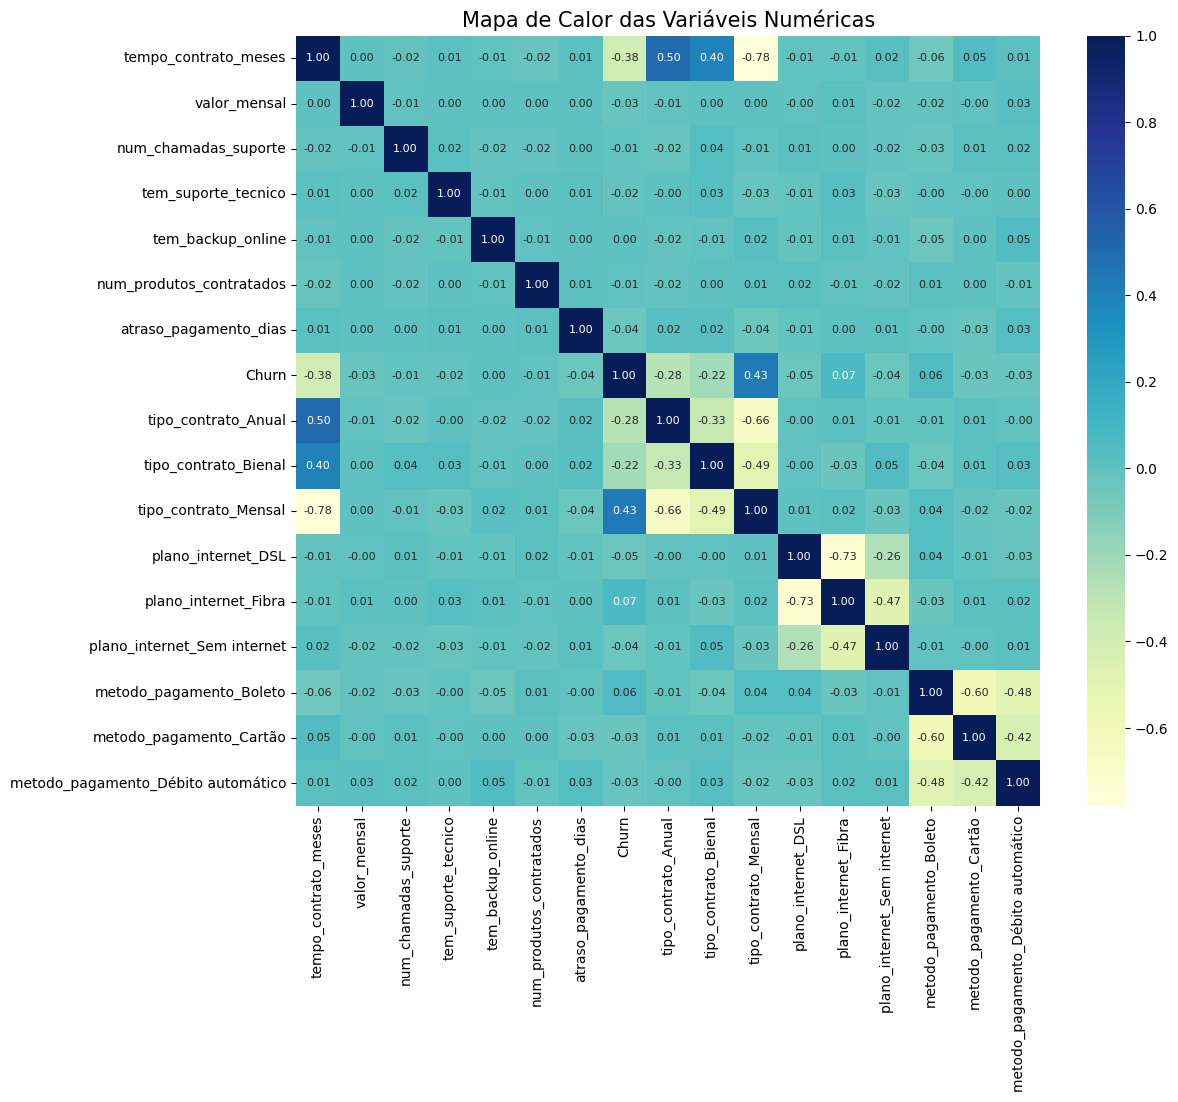

In [4]:
# Criar o Mapa de Calor
    # 1 - Definir o tamanho
plt.figure(figsize=(12,10))
    # 2 - Desenhar o mapa de calor
sns.heatmap(
    df_churn_numerico.corr("spearman"),
    annot=True,
    annot_kws={"size": 8},
    fmt=".2f",
    cmap = "YlGnBu"
)
    # 3 - Dar um titulo
plt.title("Mapa de Calor das Variáveis Numéricas", fontsize = 15)
    # 4 - Exibir o gráfico
plt.show()

In [5]:
# Primeira Análise
display(df_churn_numerico["Churn"].value_counts())
display(df_churn_numerico["Churn"].value_counts(normalize=True))



Churn
0    2190
1    1310
Name: count, dtype: int64

Churn
0    0.625714
1    0.374286
Name: proportion, dtype: float64

In [6]:
# Analise Detalhada
import plotly.express as px

for coluna in df_churn_numerico.columns:
    grafico = px.histogram(df_churn_numerico,x=coluna,color="Churn",text_auto=True,color_discrete_sequence=["red", "blue"])
    grafico.show()

In [9]:
# Clientes com plano mensal tendem a cancelar mais

# Cancelametos Originais
display(df_churn_numerico["Churn"].value_counts(normalize=True))

# Cancelametos Sem contratos mensais
condicao = df_churn_numerico["tipo_contrato_Mensal"] != True
df_churn_sem_contratos_mensais = df_churn_numerico[condicao]
display(df_churn_sem_contratos_mensais["Churn"].value_counts(normalize=True))
# Cancelamentos sem contratos mensais abaixo de 24 meses
condicao = df_churn_numerico["tempo_contrato_meses"] >= 24
df_churn_contratos_mensais_acima_de_25 = df_churn_numerico[condicao]
display(df_churn_contratos_mensais_acima_de_25["Churn"].value_counts(normalize=True))

Churn
0    0.625714
1    0.374286
Name: proportion, dtype: float64

Churn
0    0.832207
1    0.167793
Name: proportion, dtype: float64

Churn
0    0.854065
1    0.145935
Name: proportion, dtype: float64

## *Criação do Modelo de Machine Learning*

In [10]:
from sklearn.model_selection import train_test_split

# 1. Separar as features (X) da variável alvo (y)
X = df_churn_numerico.drop(columns=["Churn"])
y = df_churn_numerico["Churn"]

# 2. Dividir os dados em conjuntos de Treino (80%) e Teste (20%)
# O 'stratify=y' garante que a proporção de cancelamentos seja igual nas duas partes
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Conferir o tamanho dos blocos gerados
print(f"Total de linhas para treino: {X_train.shape[0]}")
print(f"Total de linhas para teste: {X_test.shape[0]}")

Total de linhas para treino: 2800
Total de linhas para teste: 700


## Modelo: Regressão Lógica

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Instanciar o modelo de Regressão Logística
# O 'max_iter=1000' garante que o algoritmo tem ciclos suficientes para convergir (aprender)
modelo_baseline = LogisticRegression(random_state=42, max_iter=1000)

# 2. Treinar o modelo usando os dados de treino (X_train e y_train)
modelo_baseline.fit(X_train, y_train)

# 3. Fazer previsões usando os dados de teste (X_test que o modelo nunca viu)
previsoes = modelo_baseline.predict(X_test)

# 4. Avaliar a acurácia geral do modelo
acuracia = accuracy_score(y_test, previsoes)
print(f"Acurácia do Modelo Base: {acuracia * 100:.2f}%\n")

# 5. Ver o relatório detalhado de desempenho (Precision, Recall, F1-Score)
print("Relatório de Classificação:")
print(classification_report(y_test, previsoes))

Acurácia do Modelo Base: 71.57%

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.81      0.72      0.76       438
           1       0.60      0.71      0.65       262

    accuracy                           0.72       700
   macro avg       0.70      0.71      0.71       700
weighted avg       0.73      0.72      0.72       700



## Modelo: Random Forest

In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Instanciar o modelo Random Forest
# random_state=42 garante a reprodutibilidade, e n_estimators define o número de árvores na floresta (100 é o padrão)
modelo_rf = RandomForestClassifier(n_estimators=100, random_state=42,max_depth=6,max_leaf_nodes=5)

# 2. Treinar o modelo com os dados de treino
modelo_rf.fit(X_train, y_train)

# 3. Fazer as previsões com os dados de teste
previsoes_rf = modelo_rf.predict(X_test)

# 4. Avaliar a acurácia e o relatório de classificação
acuracia_rf = accuracy_score(y_test, previsoes_rf)
print(f"Acurácia do Random Forest: {acuracia_rf * 100:.2f}%\n")

print("Relatório de Classificação (Random Forest):")
print(classification_report(y_test, previsoes_rf))

Acurácia do Random Forest: 72.00%

Relatório de Classificação (Random Forest):
              precision    recall  f1-score   support

           0       0.85      0.67      0.75       438
           1       0.59      0.80      0.68       262

    accuracy                           0.72       700
   macro avg       0.72      0.74      0.72       700
weighted avg       0.75      0.72      0.72       700

